<h1>Workshop 5 - Data Analysis</h1>

<b>This workshop is about using Python to analyse your data.</b>

We'll start by getting Python speaking to your Arduino. We'll then move on to do some data analysis. 

We'll use [scipy](https://scipy.org/) for data analysis and [matplotlib](https://matplotlib.org/) for curve fitting.

<h1>Activity 2 - Sending multiple commands to your MKR</h1>

<b>For this Activity, you'll need the Arduino code that you built in Workshop 5, Activity 1.</b> 

Alternatively, there's some Arduino pre-written code that you can use on the Workshop 5 Canvas page.

Just as in most previous weeks, your task is to get some semi-familiar Python code talking to your MKR.

## Exercise 1
Take a look at the code below and do the following:

1. Search any lines of code that you don't understand on the internet - use Google, ChatGPT, or any tool you like to understand what's happening.

1. Get the code below working for *your* computer.

1. Just like with the Arduino exercise, modify your code so that your Arduino sends:
    - 10 readings at 1 reading per second.
    - 10 readings at 5 readings per second.
    - 100 readings at 100 readings per second.

1. Use the code above to save three .csv files: 
    - `data_10.csv` (containing 10 data points) 
    - `data_100.csv` (containing 100 data points) 
    - `data_1000.csv` (containing 1000 data points) 

Example output you'll get from the code if it runs successfully is posted below.

In [ ]:
import serial
import serial.tools.list_ports
import pandas as pd
import numpy as np
import time

column_titles = ['time', 'temp', 'pressure', 'gas']
n_readings = 20
r_readings = 10

# Connect to the Nicla
ports = serial.tools.list_ports.comports()
for n in ports:
    # Print the names of the devices connected to the computer - your Nicla will be one of them.
    print(n.description)
    print(n.device)
    # You may be able to use the following lines to automatically set the Serial port:
    if 'Arduino' in n.description:
        dev = n.device

# You need to change the line below to the right Serial port for your Nicla:
dev = 'COM8'

# In general - baudrate=115200 and you shouldn't change it. You'll find tuning timeout can be useful for improving the quality of your data.
mkr = serial.Serial(port=dev, baudrate=115200, timeout=0.1)

# Clear the buffer for the Nicla serial port
mkr.flush()
mkr.reset_input_buffer()

# Send number and rate of sensor readings to the Nicla - this will tell the Nicla to start collecting data
mkr.write(bytes("{f0},{f1}".format(f0=n_readings,f1=r_readings), 'utf-8'))

# Create a numpy array to store the data
data_table = np.zeros((n_readings, len(column_titles)))
for n in range(n_readings):
    for readAttempt in range(100):
        data = mkr.readline()
        data = np.fromstring(data, sep=',')

        if len(data) == len(column_titles):
            break;
        print("Failed to read data index {} (attempt number {} out of 100). Trying again...".format(n, readAttempt+1))
        time.sleep(0.01)

    # Put the data in the nth row a numpy array
    data_table[n,:] = data

mkr.close()

# # Put the data in a DataFrame
data = pd.DataFrame(data_table, columns=column_titles)
data.to_csv('data_' + str(len(data)) + '.csv')

data

Arduino MKR WiFi 1010 (COM8)
COM8
Failed to read data index 0 (attempt number 1 out of 100). Trying again...
Failed to read data index 0 (attempt number 2 out of 100). Trying again...
Failed to read data index 0 (attempt number 3 out of 100). Trying again...
Failed to read data index 0 (attempt number 4 out of 100). Trying again...
Failed to read data index 0 (attempt number 5 out of 100). Trying again...
Failed to read data index 0 (attempt number 6 out of 100). Trying again...
Failed to read data index 0 (attempt number 7 out of 100). Trying again...
Failed to read data index 0 (attempt number 8 out of 100). Trying again...
Failed to read data index 0 (attempt number 9 out of 100). Trying again...
Failed to read data index 0 (attempt number 10 out of 100). Trying again...
Failed to read data index 0 (attempt number 11 out of 100). Trying again...
Failed to read data index 0 (attempt number 12 out of 100). Trying again...
Failed to read data index 1 (attempt number 1 out of 100). Tryi

,time,temp,pressure,gas
0,508.0,26.98,959.64,65235.0
1,718.0,26.98,959.64,65380.0
2,858.0,26.98,959.64,65380.0
3,1018.0,26.99,959.64,64996.0
4,1158.0,26.99,959.62,64853.0
5,1288.0,26.99,959.62,64853.0
6,1439.0,26.99,959.62,64996.0
7,1569.0,26.99,959.62,64996.0
8,1709.0,26.99,959.62,65332.0
9,1839.0,26.99,959.62,65332.0


<h1>Take a Break</h1>
We'll discuss the Week 5 Digital Discovery Paper.

<h1>Activity 3 - Revision of Simple Plotting</h1>



<h3>3.1 Data Filtering</h3>
Let's quickly review basic data tidying and plotting in <b>pandas</b> and <b>matplotlib</b> before doing some more complicated analysis.

Start by importing some useful modules:

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl
import numpy as np
mpl.rcParams['axes.formatter.useoffset'] = False    # Remove annoying auto-offset

### 3.2 Summarising Data with `pandas`

First - we'll use `pandas` to load our file with 1000 data points and use the `describe()` function to take a quick look at our data:

In [3]:
data = pd.read_csv('./data_1000.csv', index_col=0)
data.describe()

,time,temp,pressure,gas
count,1000.000000,1000.000000,1000.00000,1000.00000
mean,69862.726000,23.544960,1020.47512,24869.24500
std,40094.549496,0.201492,0.02722,108.61805
min,509.000000,23.210000,1020.40000,24541.00000
25%,35181.500000,23.330000,1020.46000,24802.00000
50%,69822.000000,23.610000,1020.48000,24876.00000
75%,104547.500000,23.750000,1020.49000,24935.00000
max,139264.000000,23.780000,1020.53000,25205.00000


### 3.3 Data Filtering and Basic Plotting

Now - remove statistical outliers - in the example below, we remove data from the lower and highest percentile:

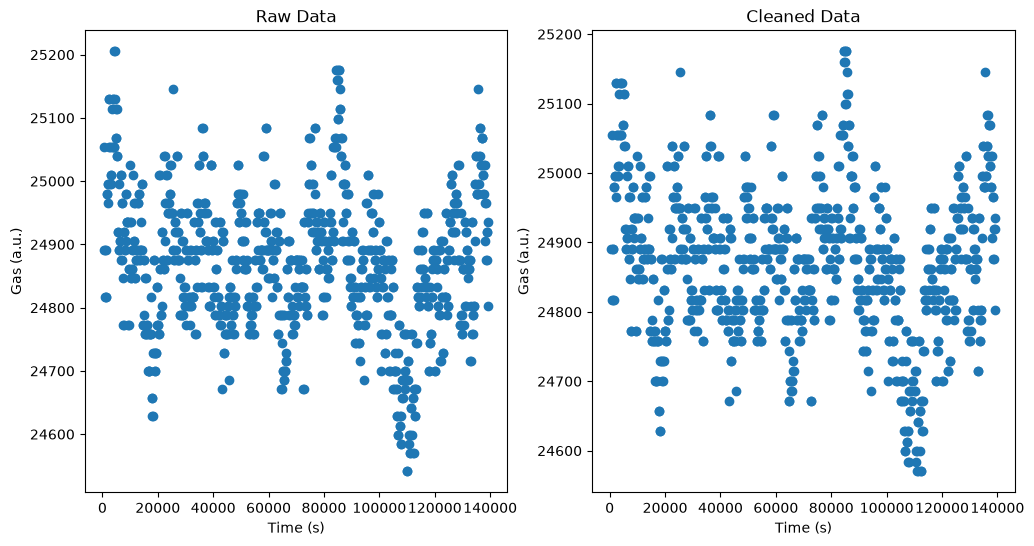

In [4]:
lower_bound = data['gas'].quantile(0.0001)
upper_bound = data['gas'].quantile(0.9999)

data_gas_clean = data[(data['gas'] > lower_bound) & (data['gas'] < upper_bound)]

fig = plt.figure(figsize=(12, 6))
ax1 = fig.add_subplot(121)
ax1.scatter(data['time'], data['gas'])
ax1.set_xlabel('Time (s)')
ax1.set_ylabel('Gas (a.u.)')
ax1.set_title('Raw Data')

ax2 = fig.add_subplot(122)
ax2.scatter(data_gas_clean['time'], data_gas_clean['gas'])
ax2.set_xlabel('Time (s)')
ax2.set_ylabel('Gas (a.u.)')
ax2.set_title('Cleaned Data')
plt.show()


## Exercise 2

Produce plots of data before and after cleaning from the other sensors that you're reading from (pressure and gas, if you're using the code given to you!) - save plots of the data from all three sensors. If you're finding your data isn't well behaved, trying plotting the smaller datasets (e.g., 100 measurements) or re-measuring using a higher measurement rate.

<h1>Activity 4 - More Complex Plotting</h1>

Now let's do some proper data visualisation and analysis.

We'll look at histograms to investigate the statistical distribution of your data points. A [histogram](https://en.wikipedia.org/wiki/Histogram) is a type of graph that, rather than plotting one variable as a function of another, gives you information about how often particular values appear in your data set. 


<h3>4.1 - Histograms</h3>
Pick the noisiest data from either your gas, pressure, or temperature sensor. In the following examples we'll use the gas sensor, but temperature and pressure may work equally well.

Let's start by visualising the noise in your data, after we've excluded outliers such as 0 values:

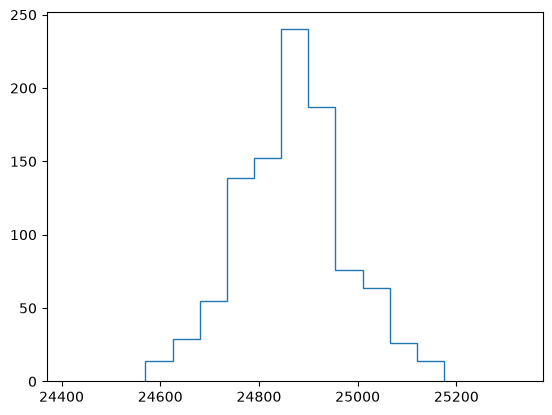

In [5]:
data = pd.read_csv('./data_1000.csv', index_col=0)

lower_bound = data['gas'].quantile(0.001)
upper_bound = data['gas'].quantile(0.999)
data_clean = data[(data['gas'] > lower_bound) & (data['gas'] < upper_bound)]

counts, bins = np.histogram(data_clean['gas'], bins=11)

fig = plt.figure()
ax = fig.add_subplot(111)
ax.stairs(counts, bins)
ax.set_xlim(bins[0]-200, bins[-1]+200)
plt.show()

## Exercise 3

First - modify the quantiles you're exluding so that you're only excluding outliers. You may find you don't need to exclude outliers at all (this was the case for the dataset that I took!)

Now - search the internet, stackoverflow, and ChatGPT to add the following features to your graphs:

1. Change the number of bars/bins in your histogram to suit your data - if you're really nailing it, you could use [Sturge's Rule](https://en.wikipedia.org/wiki/Sturges%27s_rule) to calculate how many bins there should be.
1. Title, x- and y-labels.
1. Modify the x-tick label font size so that the graph labels are clear.
1. Make the lines on histogram bars thicker.
1. Change the fill and border colours for the bars in your plot.
1. Save the plot when you're happy with it.
1. Bonus - run through this page - https://numpy.org/doc/stable/reference/generated/numpy.histogram.html - and find out how to normalise your histogram

<h3>4.2 - Curve Fitting</h3>
The next two bits are <i>tricky</i>. Read them through and work through them slowly - aim to fit a Gaussian by the end of the Workshop. The rest is work for home!

Now we'll use a Python library called `scipy` to fit a curve to our data. Specifically, we'll use `curve_fit` to fit our data using the [Levenberg-Marquardt algorithm](https://en.wikipedia.org/wiki/Levenberg%E2%80%93Marquardt_algorithm). 

A Gaussian (or 'normal') distribution is defined by the following equation:

$$f(x; \sigma, \mu) = A \ \mathrm{exp} \left ( \frac{-(x-\mu)^2}{2\sigma^2} \right )$$

where $\sigma$ is the standard deviation, $\mu$ is the mean, and $A$ is the amplitude of the Gaussian.

The code we use to fit this equation to our data is given below.

 Initial guess for our parameters 200 200 25000
Parameter values after fitting [  212.90635846    99.77234148 24867.23980242]


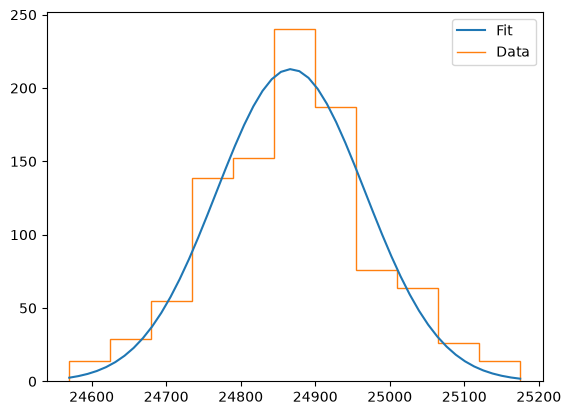

In [7]:
from scipy.optimize import curve_fit

# Define the function we're fitting
def gaussian(x, a, sigma, mu):
    return a*np.exp((-1*(x - mu)**2)/(2*sigma**2))

# Calculate the mid-points of the histogram bins - so convert it to a scatter graph
bins_midpoint = (bins[:-1] + bins[1:]) / 2.

# We need to feed the fit algorithm initial guesses of the values in our function
a_guess, std_guess, mean_guess = 200, 200, 25000

# A cheat's way of finding the initial guesses for a Gaussian is in the line below:
# a_guess, std_guess, mean_guess = data['gas'].max(), data['gas'].std(), data['gas'].mean()

print(' Initial guess for our parameters', a_guess, std_guess, mean_guess)
fit_params = np.array([a_guess, std_guess, mean_guess])

# popt - values for the mean and standard deviation of our plot
# pcov - measures how good the fit is
# Read the module documentation for full details - https://docs.scipy.org/doc/scipy/reference/generated/scipy.optimize.curve_fit.html
popt, pcov = curve_fit(gaussian, bins_midpoint, counts, p0=fit_params)
print('Parameter values after fitting', popt)

# Plot the data and the fit
fig = plt.figure()
ax = fig.add_subplot(111)
ax.plot(np.linspace(bins[0], bins[-1]), gaussian(np.linspace(bins[0], bins[-1]), popt[0], popt[1], popt[2]), label='Fit')
ax.stairs(counts, bins, label='Data')
plt.legend()
plt.show()


<h3>4.3 - Extracting Fit Coefficients</h3>
Your fit coefficients and their errors are given by the variables `popt` and `pcov`, in this line of code:

```
popt, pcov = curve_fit(gaussian, bins_midpoint, counts, p0=fit_params)
```

`popt` gives the fit coefficients in the order that they were defined. So for the gaussian we defined in the equation above:

```
def gaussian(x, a, sigma, mu):
    return a*np.exp((-1*(x - mu)**2)/(2*sigma**2))
```

`popt[0]`, `popt[1]`, and `popt[2]` gives is the amplitude, standard deviation, and mean of the Gaussian respectively

In [8]:
amplitude = popt[0]
stdev = popt[1]
mean = popt[2]

print('Amplitude is', amplitude)
print('Standard deviation is', stdev)
print('Mean is', mean)

Amplitude is 212.90635845873473
Standard deviation is 99.7723414807494
Mean is 24867.239802416178


<h3>4.4 - Calculating Fit Error</h3>
The errors in the fit coefficients are given by calculating the square root of the diagonal elements of `pcov` (it's worth printing the whole thing to see what we mean by this - I explain it a bit more below). 

Thankfully, this can be done in a single line of Python, like below:

In [15]:
# Calculate errors
perr = np.sqrt(np.diag(pcov))

a_err = perr[0]
sigma_err = perr[1]
mu_err = perr[2]

print('Amplitude is', amplitude, '±', a_err)
print('Standard deviation is', stdev, '±', sigma_err)
print('Mean is', mean, '±', mu_err)

Amplitude is 212.90635845873473 ± 15.382186750953586
Standard deviation is 99.7723414807494 ± 8.331711078814084
Mean is 24867.239802416178 ± 8.32200023543016


Strictly - `pcov` is what's a called a covariance matrix. In the above code, we've calculated the square root of the diagonal elements of it to calculate an error. 

We'll explore what this means properly in CHEM502 - for now, it's 'right enough' to just calculate a fit error using the above code. 

The truly curious should read Chapter 7 in "Measurements and their Uncertainties" by Hughes and Hase, availabile in the Library.

## Exercise 4 - Getting Curve Fitting to Work

1. Get the above code working for your data so you can fit a normal distribution to your data - you'll find you'll have to do things like change the initial guesses you feed `curve_fit()`. Remember to read through the comments, search the internet, and use the print command to understand any functions that are unfamiliar to you.

1. Hence, figure out the amplitude, mean, and standard deviation of the Gaussian that you're fitting to your data. How do they differ from the true mean and standard deviation of your data that you can calculate directly (e.g., using pandas `describe()` function, like earlier)?

1. Make your plot pretty - just like you did in Exercise 3. 

Congratulations - you've just done your first bit of machine learning!


## Stretch Goal - Exercise 5 - Exploring How Number of Measurements Affects Fitting

It may be that your data isn't well-fitted by a Gaussian distribution - there are lots of reasons that this might happen, but there are 3 key reasons that you're likely to encounter here:

<b>Insufficient Data</b>

Gaussians only appear when you have a large number of measurements. If you only have 20 or so

<b>Too Many Bins</b>

To calculate your histograms, your data is divided into bins. In the example in 4.1, we set `n_bins=11` - meaning there are 11 bins into which the data is placed. As a rule of thumb, a dataset of $N$ datapoints should have no more than $\sqrt{N}$ bins. If you're fitting a curve with a peak (e.g., a Gaussian), you should have an odd number of bins.

<b>Multi-Modal Data</b>

If something <i>changes</i> during the measurement (e.g., the room warms up or a door opens) your system will end up measuring multiple different values, each with some noise associated with it. One way of modelling this is to use two (or more) Gaussians - where the mean of each Gaussian corresponds to the value of each measurement, and the standard deviation corresponds to the noise in each measurement.

### And now for the actual exercise...
1. Change the number and rate of readings you get from your Arduino to get 3 data sets, a small one (10ish readings), a medium one (100ish readings), and a large one (1000ish) that all look fairly Guassian (this may not be feasible for the small data set - which is fine).

1. Fit Gaussians to each data set, and extract the fit coefficients and their errors.

1. Plot two separate graphs - one showing how your different fit coefficients vary with the size of the dataset, and another showing how fit error varies with the size of the dataset.



<h1>End of the Workshop</h1>
Your homework is to start planning your projects. Everything below is bonus content!